# Partie 2 · Étape 1 : fiabiliser le portefeuille de crédit BNDE

**Suite de [TP-BNDE](https://github.com/Matar18/TP-BNDE)** (exploration, nettoyage et profilage de 500 crédits).

La partie 1 concluait : *aucune variable ne sépare, à elle seule, les bons et les mauvais payeurs ; avant de parler scoring, il faut fiabiliser la donnée.*
Ce notebook fait exactement ça, en trois temps :

1. **Contrôler** : transformer les anomalies repérées « à la main » en partie 1 en **12 règles automatiques**, rejouables sur n'importe quel portefeuille.
2. **Mesurer l'impact** : combien de crédits sont concernés, et que se passe-t-il sur le **provisionnement** si on corrige les statuts ?
3. **Livrer** : un portefeuille fiabilisé (rien n'est supprimé, tout est tracé) et un rapport d'anomalies exploitable par la banque.

> Le notebook `02_premier_score.ipynb` utilise ensuite ces données pour tester un premier modèle de scoring.

## 1. Chargement

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.chargement import charger_donnees
from src.controles import (REGLES, SEUIL_IMPAYE_DOUTEUX_J, TAUX_USURE_BANQUES_PCT,
                           SEUIL_ENDETTEMENT_ALERTE, executer_controles, synthese_controles, fiabiliser)
from src.provisions import comparer_scenarios
from src.graphiques import appliquer_style, COULEURS_STATUT, COULEURS_GRAVITE, BLEU, GRIS, ENCRE_2

appliquer_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 90)
FIGURES, SORTIES = RACINE / "figures", RACINE / "outputs"
FIGURES.mkdir(exist_ok=True); SORTIES.mkdir(exist_ok=True)

In [2]:
df, nb_doublons = charger_donnees(RACINE / "data" / "dataset_BNDE.csv")
print(f"{nb_doublons} doublons supprimés -> {len(df)} crédits, {df.shape[1]} variables")
df.head()

3 doublons supprimés -> 500 crédits, 12 variables


,Client_ID,Age,Region,Secteur_Activite,Revenu_Mensuel,Montant_Credit,Duree_Mois,Taux_Interet,Nb_Credits_Anterieurs,Garantie,Retard_Paiement_Jours,Statut_Credit
0,CLI0001,60.0,Thiès,Agriculture,395000.0,5000000,60,15.89,4,Immobilière,2,Douteux
1,CLI0002,50.0,Dakar,Agriculture,489000.0,500000,36,16.92,2,Non renseignée,4,Douteux
2,CLI0003,36.0,Ziguinchor,BTP,495000.0,500000,12,12.34,1,Immobilière,30,Bon
3,CLI0004,64.0,Kaolack,Services,734000.0,500000,36,17.10,2,Mobilière,39,Douteux
4,CLI0005,29.0,Dakar,Agriculture,433000.0,1000000,12,11.77,4,Mobilière,8,Bon


Différences volontaires avec la partie 1 :

- **On garde `Age`** (15 valeurs manquantes) : c'est une information connue à l'octroi, utile pour le score. Les manquants seront imputés dans le modèle.
- **Les garanties vides deviennent « Non renseignée »** et non « Pas de garantie » : on ne sait pas si le client n'a vraiment pas de garantie ou si le champ a été oublié. Ce doute est lui-même une anomalie.
- **On ne corrige plus les revenus négatifs par valeur absolue.** C'était une hypothèse (erreur de signe) impossible à vérifier sans le dossier. On préfère les signaler et les mettre à vide.

## 2. Les 12 règles de contrôle

Chaque règle a un **code**, une **gravité** et une **référence** (réglementaire quand elle existe). Elles sont définies une seule fois dans `src/controles.py`.

| Gravité | Signification |
|---|---|
| **Critique** | valeur impossible ou erreur de classement réglementaire certaine |
| **Élevée** | non-conformité probable ou incohérence forte, à vérifier en priorité |
| **Modérée** | alerte métier : pas forcément une erreur, mais doit être justifiée |
| **Information** | donnée manquante ou ambiguë |

Les seuils sont des paramètres modifiables : 90 jours d'impayé (Instruction BCEAO n°026-11-2016, art. 8), taux d'usure bancaire de 15 % (14 % pour les crédits accordés depuis le 1er juin 2026) et taux d'endettement d'alerte à 33 %. Ce dernier seuil est une **hypothèse de travail** inspirée de la pratique bancaire, pas une règle BCEAO.

In [3]:
pd.DataFrame([{"Code": r.code, "Contrôle": r.libelle, "Gravité": r.gravite, "Référence": r.reference}
              for r in REGLES])

,Code,Contrôle,Gravité,Référence
0,R01,Revenu négatif ou nul,Critique,Valeur impossible
1,R02,Statut « Bon » avec impayé > 90 jours,Critique,"Instruction BCEAO 026-11-2016, art. 8 : déclassement obligatoire en douteux"
2,R03,Montant de crédit extrême,Élevée,Valeur très éloignée (Q3 + 3 x IQR)
3,R04,Taux > taux d'usure bancaire (15 %),Élevée,"Loi sur l'usure UMOA (apprécié sur le TEG, toujours >= taux nominal)"
4,R05,Mensualité supérieure au revenu,Élevée,Incohérence revenu / montant
5,R06,Revenu extrême,Modérée,Valeur très éloignée (Q3 + 3 x IQR)
6,R07,Taux d'endettement entre 33% et 100 %,Modérée,"Pratique bancaire courante (~1/3 du revenu), hypothèse de travail"
7,R08,Déclassé sans impayé > 90 jours,Modérée,"Instruction BCEAO 026-11-2016, art. 8-1° et 9 : possible si risque avéré, à justifier"
8,R09,Revenu manquant,Information,Donnée manquante
9,R10,Taux d'intérêt manquant,Information,Donnée manquante


## 3. Résultat des contrôles

In [4]:
portefeuille, rapport = executer_controles(df)
synthese = synthese_controles(portefeuille)
synthese.drop(columns="Reference")

,Code,Anomalie,Gravite,Nb_credits,Part_portefeuille_%,Montant_concerne_MFCFA
0,R01,Revenu négatif ou nul,Critique,5,1.0,18.5
1,R02,Statut « Bon » avec impayé > 90 jours,Critique,2,0.4,2.0
2,R03,Montant de crédit extrême,Élevée,1,0.2,95.0
3,R04,Taux > taux d'usure bancaire (15 %),Élevée,156,31.2,596.5
4,R05,Mensualité supérieure au revenu,Élevée,40,8.0,432.0
5,R06,Revenu extrême,Modérée,1,0.2,1.0
6,R07,Taux d'endettement entre 33% et 100 %,Modérée,139,27.8,876.0
7,R08,Déclassé sans impayé > 90 jours,Modérée,176,35.2,643.5
8,R09,Revenu manquant,Information,20,4.0,78.5
9,R10,Taux d'intérêt manquant,Information,10,2.0,50.0


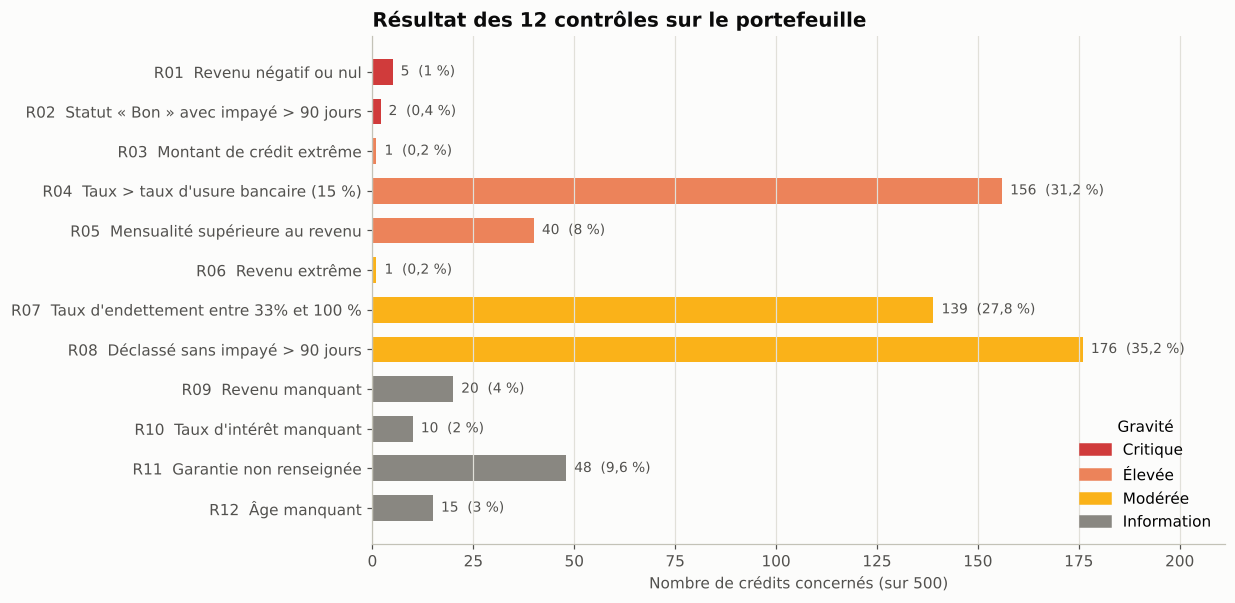

In [5]:
s = synthese.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
barres = ax.barh(s["Code"] + "  " + s["Anomalie"], s["Nb_credits"],
                 color=s["Gravite"].map(COULEURS_GRAVITE), height=0.65)
for b, n, pct in zip(barres, s["Nb_credits"], s["Part_portefeuille_%"]):
    ax.text(b.get_width() + 2, b.get_y() + b.get_height() / 2, f"{n}  ({pct:g} %)".replace(".", ","),
            va="center", fontsize=9, color=ENCRE_2)
ax.set_xlim(0, s["Nb_credits"].max() * 1.2)
ax.set_xlabel("Nombre de crédits concernés (sur 500)")
ax.set_title("Résultat des 12 contrôles sur le portefeuille")
ax.grid(axis="y", visible=False)
poignees = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COULEURS_GRAVITE.values()]
ax.legend(poignees, COULEURS_GRAVITE.keys(), title="Gravité", loc="lower right")
fig.savefig(FIGURES / "01_synthese_controles.png")
plt.show()

In [6]:
gravite = portefeuille["Gravite_Max"].value_counts().reindex(
    ["Critique", "Élevée", "Modérée", "Information", "Aucune"]).rename("Nb_credits").to_frame()
gravite["Part_%"] = (100 * gravite["Nb_credits"] / len(portefeuille)).round(1)
gravite

,Nb_credits,Part_%
Gravite_Max,,
Critique,7,1.4
Élevée,184,36.8
Modérée,156,31.2
Information,29,5.8
Aucune,124,24.8


**Lecture.** Seuls **124 crédits sur 500 (25 %)** passent tous les contrôles sans aucune remarque.

- **7 anomalies critiques** : 5 revenus impossibles (négatifs ou nuls) et 2 crédits classés « Bon » malgré plus de 90 jours d'impayé.
- Trois contrôles touchent **un tiers du portefeuille** : taux au-dessus du taux d'usure, déclassements non expliqués par l'impayé, taux d'endettement élevé.

Les trois sections suivantes zooment sur ces trois points.

## 4. Zoom 1 : le statut ne suit pas l'impayé

La règle de base de la BCEAO est simple : jusqu'à 90 jours d'impayé, la créance reste saine (art. 4) ; au-delà, elle **doit** être déclassée en douteuse (art. 8). Une banque peut aussi déclasser un crédit **sans** impayé, mais seulement si elle a un motif documenté : procédure collective, difficultés graves du client, etc. (art. 8-1° et art. 9).

On compare donc le statut déclaré avec le statut qu'impose le seul critère de l'impayé.

In [7]:
tranche = np.where(portefeuille["Retard_Paiement_Jours"] > SEUIL_IMPAYE_DOUTEUX_J, "Impayé > 90 j", "Impayé ≤ 90 j")
pd.crosstab(portefeuille["Statut_Credit"], tranche, margins=True, margins_name="Total")

col_0,Impayé > 90 j,Impayé ≤ 90 j,Total
Statut_Credit,,,
Bon,2,322,324
Douteux,0,126,126
Contentieux,0,50,50
Total,2,498,500


In [8]:
portefeuille.groupby("Statut_Credit", observed=True)["Retard_Paiement_Jours"].describe()[["count", "50%", "75%", "max"]]

,count,50%,75%,max
Statut_Credit,,,,
Bon,324.0,9.5,17.25,980.0
Douteux,126.0,9.0,17.00,81.0
Contentieux,50.0,13.0,24.00,72.0


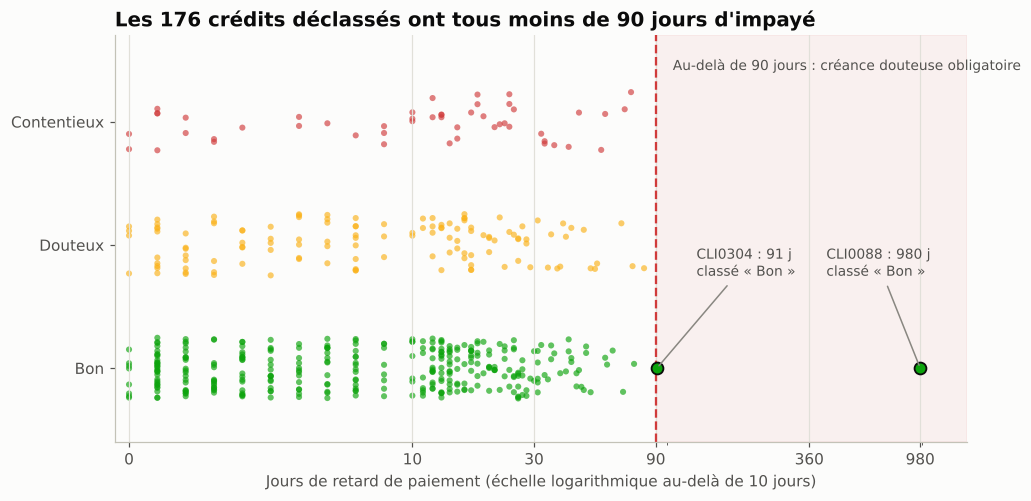

In [9]:
rng = np.random.default_rng(42)
statuts = ["Bon", "Douteux", "Contentieux"]
fig, ax = plt.subplots(figsize=(10, 4.8))
mal_classes = portefeuille["R02"]
for i, statut in enumerate(statuts):
    r = portefeuille.loc[(portefeuille["Statut_Credit"] == statut) & ~mal_classes, "Retard_Paiement_Jours"]
    ax.scatter(r, i + rng.uniform(-0.25, 0.25, len(r)), s=16, alpha=0.65,
               color=COULEURS_STATUT[statut], edgecolor="none")
# Les 2 crédits « Bon » au-delà de 90 jours, mis en évidence
ax.scatter(portefeuille.loc[mal_classes, "Retard_Paiement_Jours"], np.zeros(mal_classes.sum()), s=60,
           color=COULEURS_STATUT["Bon"], edgecolor="#0b0b0b", linewidth=1.2, zorder=3)
ax.set_xscale("symlog", linthresh=10)
ax.axvspan(SEUIL_IMPAYE_DOUTEUX_J + 0.5, 1500, color=COULEURS_STATUT["Contentieux"], alpha=0.06)
ax.axvline(SEUIL_IMPAYE_DOUTEUX_J + 0.5, color=COULEURS_STATUT["Contentieux"], lw=1.5, ls="--")
ax.text(105, 2.42, "Au-delà de 90 jours : créance douteuse obligatoire", fontsize=9, color=ENCRE_2)
for cid, x_texte in [("CLI0304", 130), ("CLI0088", 420)]:
    j = int(portefeuille.loc[portefeuille["Client_ID"] == cid, "Retard_Paiement_Jours"].iloc[0])
    ax.annotate(f"{cid} : {j} j\nclassé « Bon »", xy=(j, 0), xytext=(x_texte, 0.75), fontsize=9,
                color=ENCRE_2, arrowprops=dict(arrowstyle="-", color=GRIS, lw=1))
ax.set_yticks(range(3), statuts)
ax.set_ylim(-0.6, 2.7)
ax.set_xlim(-0.5, 1500)
ax.set_xticks([0, 10, 30, 90, 360, 980])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.0f}"))
ax.set_xlabel("Jours de retard de paiement (échelle logarithmique au-delà de 10 jours)")
ax.set_title("Les 176 crédits déclassés ont tous moins de 90 jours d'impayé")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "02_statut_vs_impaye.png")
plt.show()

**Lecture.** C'est la découverte la plus importante de cette étape.

- **Les 176 crédits Douteux ou Contentieux ont tous moins de 90 jours d'impayé** (maximum : 81 jours). Aucun n'est déclassé à cause de l'impayé.
- À l'inverse, **2 crédits ont dépassé 90 jours et sont restés « Bon »** : CLI0088 (980 jours) et CLI0304 (91 jours). Pour eux, le déclassement est obligatoire.
- Les retards médians sont quasi identiques d'un statut à l'autre (9 à 13 jours).

Deux explications sont possibles, et toutes les deux posent problème :

1. **Le statut repose sur un jugement d'expert** (risque avéré sans impayé). C'est autorisé, mais le motif doit être documenté. Or le dataset ne contient aucun motif.
2. **Le statut est mal saisi.** Dans ce cas, le taux de défaut de 35 % est faux.

Dans les deux cas, **on ne peut pas utiliser ce statut tel quel comme cible d'un modèle de scoring** sans l'avoir fait valider par la banque. On le vérifie dans le notebook 2.

## 5. Zoom 2 : des taux au-dessus du taux d'usure

Dans l'UMOA, le taux d'usure des banques était de **15 %** jusqu'au 31 mai 2026. Il est de **14 %** depuis le 1er juin 2026 (décision n°19 du Conseil des Ministres de l'UMOA du 29 décembre 2025). Ce plafond s'applique au **taux effectif global (TEG)**, qui inclut les frais et est donc toujours supérieur ou égal au taux nominal.

Conséquence : si le taux nominal dépasse déjà 15 %, le TEG aussi.

In [10]:
taux = portefeuille["Taux_Interet"].dropna()
print(f"Taux renseignés : {len(taux)}")
print(f"> 15 % : {(taux > 15).sum()} crédits ({(taux > 15).mean():.1%} des taux renseignés)")
print(f"> 14 % : {(taux > 14).sum()} crédits (nouveau plafond pour les crédits accordés depuis juin 2026)")

Taux renseignés : 490
> 15 % : 156 crédits (31.8% des taux renseignés)
> 14 % : 202 crédits (nouveau plafond pour les crédits accordés depuis juin 2026)


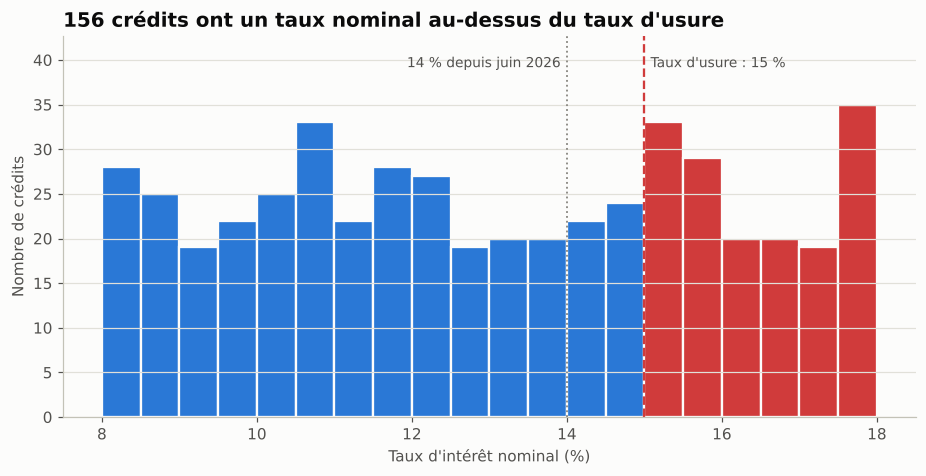

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bornes = np.arange(8, 18.5, 0.5)
n, b, patches = ax.hist(taux, bins=bornes, color=BLEU, edgecolor="#fcfcfb", linewidth=1.5)
for p, gauche in zip(patches, b[:-1]):
    if gauche >= TAUX_USURE_BANQUES_PCT:
        p.set_facecolor(COULEURS_GRAVITE["Critique"])
ax.axvline(TAUX_USURE_BANQUES_PCT, color=COULEURS_GRAVITE["Critique"], lw=1.5, ls="--")
ax.axvline(14, color=GRIS, lw=1.2, ls=":")
ax.set_ylim(0, n.max() * 1.22)
ax.text(15.08, n.max() * 1.12, "Taux d'usure : 15 %", fontsize=9, color=ENCRE_2)
ax.text(13.92, n.max() * 1.12, "14 % depuis juin 2026", fontsize=9, color=ENCRE_2, ha="right")
ax.set_xlabel("Taux d'intérêt nominal (%)")
ax.set_ylabel("Nombre de crédits")
ax.set_title("156 crédits ont un taux nominal au-dessus du taux d'usure")
ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "03_taux_usure.png")
plt.show()

In [12]:
# Le dépassement du taux d'usure est-il lié au statut ?
t = portefeuille.dropna(subset=["Taux_Interet"])
pd.crosstab(np.where(t["Taux_Interet"] > TAUX_USURE_BANQUES_PCT, "Taux > 15 %", "Taux ≤ 15 %"),
            t["Statut_Credit"], normalize="index").mul(100).round(1)

Statut_Credit,Bon,Douteux,Contentieux
row_0,,,
Taux > 15 %,65.4,25.6,9.0
Taux ≤ 15 %,64.7,24.6,10.8


**Lecture.** **156 crédits, près d'un tiers du portefeuille**, affichent un taux nominal au-dessus de 15 %. La part de bons payeurs est la même que pour le reste du portefeuille (65,4 % contre 64,7 %) : ce n'est donc pas un « taux de risque » appliqué aux clients fragiles.

Ce n'est pas forcément une infraction : le taux peut être mal saisi (TEG annuel confondu avec un autre taux, crédit relevant d'un autre régime...). Mais c'est **la question à poser en premier à la banque**, car une non-conformité à la loi sur l'usure a des conséquences juridiques directes.

## 6. Zoom 3 : la capacité de remboursement n'est pas prise en compte

On calcule la **mensualité** de chaque crédit (formule d'un prêt amortissable à échéances constantes), puis le **taux d'endettement** = mensualité / revenu mensuel.

In [13]:
p = portefeuille
revenu_valide = p["Revenu_Mensuel"].where(p["Revenu_Mensuel"] > 0)
rho = p["Montant_Credit"].corr(revenu_valide, method="spearman")
print(f"Corrélation de Spearman entre montant accordé et revenu : {rho:.2f}")
p["Taux_Endettement"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).to_frame().T.round(2)

Corrélation de Spearman entre montant accordé et revenu : -0.03


,count,mean,std,min,25%,50%,75%,90%,max
Taux_Endettement,465.0,0.45,1.08,0.0,0.08,0.21,0.49,0.98,19.51


In [14]:
# Montant médian accordé selon la tranche de revenu
tranches = pd.cut(revenu_valide, [0, 300_000, 450_000, 600_000, np.inf],
                  labels=["< 300 k", "300-450 k", "450-600 k", "> 600 k"])
p.groupby(tranches, observed=True)["Montant_Credit"].agg(["count", "median", "mean"]).round(0)

,count,median,mean
Revenu_Mensuel,,,
< 300 k,86,2000000.0,4447674.0
300-450 k,137,2000000.0,3660584.0
450-600 k,146,2000000.0,3965753.0
> 600 k,106,2000000.0,3415094.0


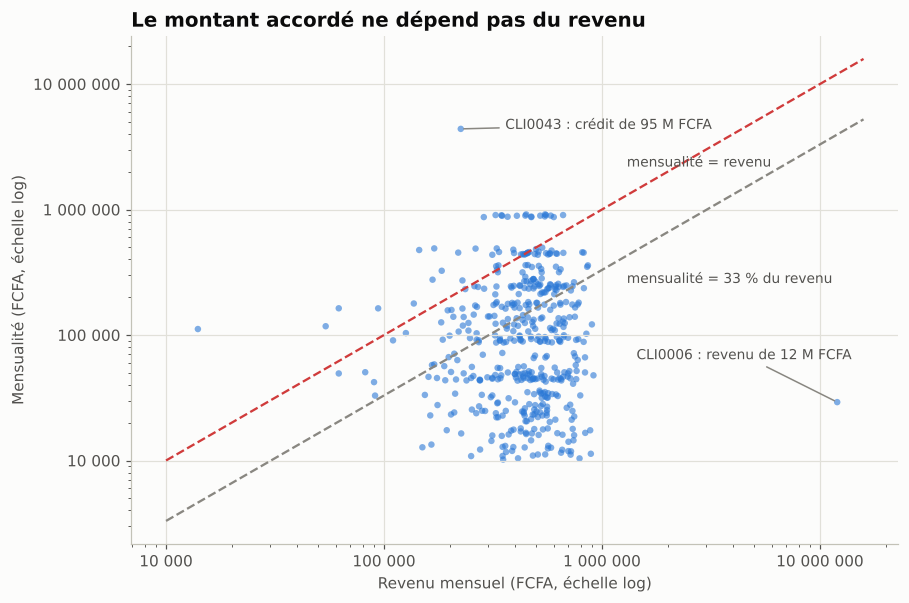

In [15]:
v = p[(p["Revenu_Mensuel"] > 0) & p["Mensualite"].notna()]
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(v["Revenu_Mensuel"], v["Mensualite"], s=18, alpha=0.6, color=BLEU, edgecolor="none")
x = np.logspace(4, 7.2, 50)
ax.plot(x, x, color=COULEURS_GRAVITE["Critique"], lw=1.5, ls="--")
ax.plot(x, SEUIL_ENDETTEMENT_ALERTE * x, color=GRIS, lw=1.5, ls="--")
ax.text(1.3e6, 2.2e6, "mensualité = revenu", fontsize=9, color=ENCRE_2)
ax.text(1.3e6, 2.6e5, "mensualité = 33 % du revenu", fontsize=9, color=ENCRE_2)
for cid, texte, decalage in [("CLI0043", "CLI0043 : crédit de 95 M FCFA", (1.6, 1.0)),
                             ("CLI0006", "CLI0006 : revenu de 12 M FCFA", (0.12, 2.2))]:
    r = v.loc[v["Client_ID"] == cid].iloc[0]
    ax.annotate(texte, xy=(r["Revenu_Mensuel"], r["Mensualite"]), fontsize=9, color=ENCRE_2,
                xytext=(r["Revenu_Mensuel"] * decalage[0], r["Mensualite"] * decalage[1]),
                arrowprops=dict(arrowstyle="-", color=GRIS, lw=1))
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.set_xlabel("Revenu mensuel (FCFA, échelle log)")
ax.set_ylabel("Mensualité (FCFA, échelle log)")
ax.set_title("Le montant accordé ne dépend pas du revenu")
fig.savefig(FIGURES / "04_endettement.png")
plt.show()

**Lecture.**

- La corrélation entre montant accordé et revenu est **nulle** : les montants accordés sont les mêmes quelle que soit la tranche de revenu.
- Résultat : **40 crédits ont une mensualité supérieure au revenu** du client, et **139 autres** dépassent 33 % d'endettement.

Soit les revenus saisis ne sont pas les bons (revenu individuel au lieu du revenu du ménage ou de l'entreprise ?), soit la capacité de remboursement n'est pas analysée à l'octroi. Les deux hypothèses sont à vérifier avec la banque.

## 7. Impact sur le provisionnement

Une erreur de classement n'est pas qu'un problème de qualité : elle change le montant que la banque doit mettre de côté. L'Instruction BCEAO n°026-11-2016 (art. 16) fixe un **calendrier minimal de provisionnement** des créances douteuses :

| Créance douteuse | Provision minimale |
|---|---|
| **Sans garantie éligible** | 20 % au déclassement, 50 % trois mois après, 100 % neuf mois après |
| **Avec garantie éligible** (hypothèque de 1er rang...) | facultative les 2 premières années, 50 % la 3e année, 100 % à partir de la 4e |

Le dataset ne contient ni l'encours restant dû, ni la date de déclassement, ni la valeur des garanties. On pose donc des **hypothèses**, toutes détaillées dans `src/provisions.py` :

- exposition = montant initial (c'est un majorant de l'encours) ;
- seule la garantie « Immobilière » est éligible (hypothèque de 1er rang supposée) ;
- un crédit déclassé sans impayé est supposé déclassé aujourd'hui, ce qui donne la provision **plancher**.

On compare trois scénarios :

- **A** : le statut déclaré ;
- **B** : le statut corrigé, c'est-à-dire A plus les 2 déclassements obligatoires ;
- **C** : un statut fondé uniquement sur l'impayé.

In [16]:
fiable = fiabiliser(portefeuille)
scenarios = comparer_scenarios(fiable)
scenarios

,Scenario,Nb_credits_douteux,Taux_douteux_%,Montant_douteux_MFCFA,Provision_min_MFCFA
0,A. Statut déclaré,176,35.2,643.5,67.8
1,B. Statut corrigé (A + déclassements obligatoires),178,35.6,645.5,68.3
2,C. Impayé > 90 j uniquement,2,0.4,2.0,0.5


In [17]:
# Sensibilité à l'hypothèse sur les garanties éligibles
hypotheses = {
    "Aucune garantie éligible": set(),
    "Immobilière seule (défaut)": {"Immobilière"},
    "Toutes les garanties": {"Immobilière", "Mobilière", "Caution"},
}
sensibilite = pd.concat(
    {nom: comparer_scenarios(fiable, g).set_index("Scenario")["Provision_min_MFCFA"] for nom, g in hypotheses.items()},
    axis=1)
sensibilite

,Aucune garantie éligible,Immobilière seule (défaut),Toutes les garanties
Scenario,,,
A. Statut déclaré,128.7,67.8,6.7
B. Statut corrigé (A + déclassements obligatoires),129.9,68.3,7.2
C. Impayé > 90 j uniquement,1.2,0.5,0.5


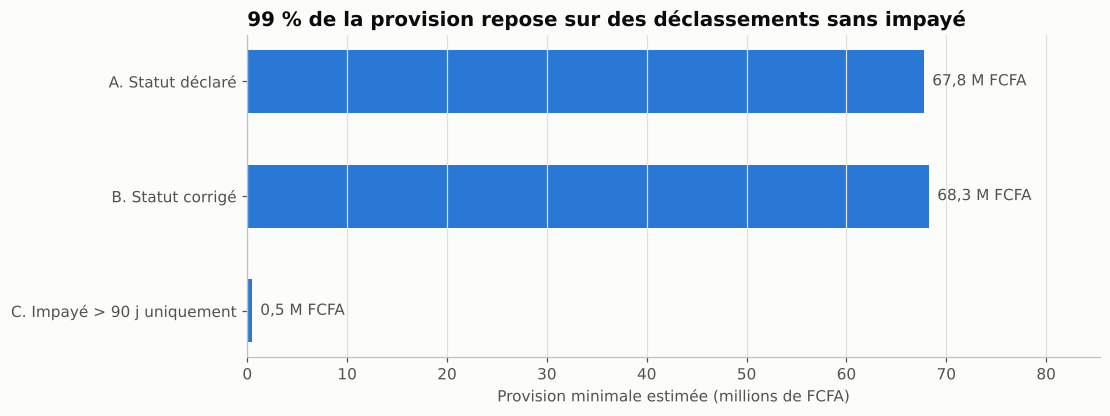

In [18]:
fig, ax = plt.subplots(figsize=(10, 3.8))
noms = ["A. Statut déclaré", "B. Statut corrigé", "C. Impayé > 90 j uniquement"]
valeurs = scenarios["Provision_min_MFCFA"].values
barres = ax.barh(noms[::-1], valeurs[::-1], color=BLEU, height=0.55)
for b, v in zip(barres, valeurs[::-1]):
    ax.text(b.get_width() + 0.8, b.get_y() + b.get_height() / 2, f"{v:.1f} M FCFA".replace(".", ","), va="center", fontsize=10, color=ENCRE_2)
ax.set_xlim(0, valeurs.max() * 1.25)
ax.set_xlabel("Provision minimale estimée (millions de FCFA)")
ax.set_title("99 % de la provision repose sur des déclassements sans impayé")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "05_provisions_scenarios.png")
plt.show()

**Lecture.**

- **Corriger les 2 crédits mal classés** (scénario B) ajoute environ **0,5 M FCFA** de provision minimale, et jusqu'à 1,2 M FCFA si l'hypothèque n'est pas jugée éligible. CLI0088, avec 980 jours d'impayé, devrait déjà être provisionné à 50 % (garantie éligible) ou à 100 % (sans garantie).
- Surtout, **la quasi-totalité de la provision (67,8 M sur 68,3 M FCFA, soit 99 %)** porte sur des crédits déclassés **sans impayé de plus de 90 jours**. Si ces déclassements sont justifiés, la banque doit pouvoir le prouver au superviseur ; s'ils sont faux, elle immobilise des fonds propres pour rien.

Le montant exact dépend fortement des hypothèses : de 7 à 130 M FCFA selon les garanties jugées éligibles. En revanche, la conclusion ne change pas : **le provisionnement dépend d'une donnée qu'on ne sait pas expliquer.**

## 8. Livrables : portefeuille fiabilisé et rapport d'anomalies

Rien n'est supprimé. Chaque crédit garde ses valeurs d'origine, et on ajoute :

- `Revenu_Fiabilise` : vide si le revenu est impossible ;
- `Statut_Corrige` et `Motif_Statut` : le statut après application de l'art. 8, et pourquoi ;
- une colonne par règle (R01 à R12), `Nb_Anomalies` et `Gravite_Max` ;
- `Hors_Perimetre_Modele` : les 9 lignes à exclure de l'entraînement d'un score (anomalies R01, R02, R03, R06).

Les fichiers CSV utilisent le séparateur `;` et la virgule décimale : ils s'ouvrent directement dans Excel.

In [19]:
COLONNES = ["Client_ID", "Region", "Secteur_Activite", "Age", "Revenu_Mensuel", "Revenu_Fiabilise",
            "Montant_Credit", "Duree_Mois", "Taux_Interet", "Mensualite", "Taux_Endettement", "Garantie",
            "Nb_Credits_Anterieurs", "Retard_Paiement_Jours", "Statut_Credit", "Statut_Reglementaire_Impaye",
            "Statut_Corrige", "Motif_Statut", "Nb_Anomalies", "Gravite_Max", "Hors_Perimetre_Modele"] + [r.code for r in REGLES]

export = dict(sep=";", index=False, encoding="utf-8-sig", decimal=",")
fiable[COLONNES].round(4).to_csv(SORTIES / "portefeuille_fiabilise.csv", **export)
rapport.to_csv(SORTIES / "rapport_anomalies.csv", **export)
synthese.to_csv(SORTIES / "synthese_controles.csv", **export)
scenarios.to_csv(SORTIES / "provisions_scenarios.csv", **export)

print(f"portefeuille_fiabilise.csv : {len(fiable)} lignes")
print(f"rapport_anomalies.csv      : {len(rapport)} anomalies")
rapport.head(10)

portefeuille_fiabilise.csv : 500 lignes
rapport_anomalies.csv      : 613 anomalies


,Client_ID,Code,Anomalie,Gravite,Variable,Valeur,Statut_Credit,Reference,Action
0,CLI0152,R01,Revenu négatif ou nul,Critique,Revenu_Mensuel,-63000.0,Douteux,Valeur impossible,Retrouver le revenu dans le dossier. En attendant : mis à vide (pas de valeur absolue).
1,CLI0192,R01,Revenu négatif ou nul,Critique,Revenu_Mensuel,-71000.0,Douteux,Valeur impossible,Retrouver le revenu dans le dossier. En attendant : mis à vide (pas de valeur absolue).
2,CLI0251,R01,Revenu négatif ou nul,Critique,Revenu_Mensuel,0.0,Bon,Valeur impossible,Retrouver le revenu dans le dossier. En attendant : mis à vide (pas de valeur absolue).
3,CLI0437,R01,Revenu négatif ou nul,Critique,Revenu_Mensuel,-10000.0,Douteux,Valeur impossible,Retrouver le revenu dans le dossier. En attendant : mis à vide (pas de valeur absolue).
4,CLI0446,R01,Revenu négatif ou nul,Critique,Revenu_Mensuel,-16000.0,Bon,Valeur impossible,Retrouver le revenu dans le dossier. En attendant : mis à vide (pas de valeur absolue).
5,CLI0088,R02,Statut « Bon » avec impayé > 90 jours,Critique,Retard_Paiement_Jours,980,Bon,"Instruction BCEAO 026-11-2016, art. 8 : déclassement obligatoire en douteux",Déclasser en Douteux et constituer la provision.
6,CLI0304,R02,Statut « Bon » avec impayé > 90 jours,Critique,Retard_Paiement_Jours,91,Bon,"Instruction BCEAO 026-11-2016, art. 8 : déclassement obligatoire en douteux",Déclasser en Douteux et constituer la provision.
7,CLI0043,R03,Montant de crédit extrême,Élevée,Montant_Credit,95000000,Bon,Valeur très éloignée (Q3 + 3 x IQR),Vérifier le contrat (zéro en trop ?).
8,CLI0001,R04,Taux > taux d'usure bancaire (15 %),Élevée,Taux_Interet,15.89,Douteux,"Loi sur l'usure UMOA (apprécié sur le TEG, toujours >= taux nominal)",Vérifier le TEG et la date d'octroi. Si confirmé : crédit non conforme.
9,CLI0002,R04,Taux > taux d'usure bancaire (15 %),Élevée,Taux_Interet,16.92,Douteux,"Loi sur l'usure UMOA (apprécié sur le TEG, toujours >= taux nominal)",Vérifier le TEG et la date d'octroi. Si confirmé : crédit non conforme.


## 9. Conclusion de l'étape 1 : ce qu'on demande à la banque

| Priorité | Question | Signalements |
|---|---|---|
| 1 | Ces taux dépassent-ils vraiment le taux d'usure (TEG, date d'octroi) ? | 156 |
| 2 | Quel est le motif de déclassement des crédits Douteux / Contentieux sans impayé > 90 jours ? | 176 |
| 3 | Déclasser et provisionner CLI0088 et CLI0304 (impayé > 90 jours) | 2 |
| 4 | Corriger les revenus impossibles et vérifier les montants / revenus extrêmes (CLI0043, CLI0006) | 7 |
| 5 | Le revenu saisi est-il le bon (40 mensualités supérieures au revenu) ? | 179 |
| 6 | Compléter les données manquantes et préciser les garanties vides | 93 |

**À retenir :** la question n'est plus « quelles variables expliquent le défaut ? » mais **« le statut de défaut est-il fiable ? »**. Le notebook 2 montre ce qui se passe quand on essaie quand même de construire un score dessus.